# 06 · Who responds? Segment effects and an uplift model

Notebook 03 showed that both emails work **on average**. Targeting needs more: does the effect differ between customers, and can we predict who will respond?

This notebook answers that in two steps:

1. **Pre-specified segment effects** (this section): effects within the segments named in the design document *before* looking at results: past-year spend (`history_segment`), purchase `channel`, and past purchase category (`purchase_group`: mens only, womens only, or both). Simple, transparent, and a benchmark for the model.
2. **An uplift model** (next sections): predicts each customer's individual effect from all pre-treatment features, evaluated on held-out data.

Metrics: **visit** (precise) and **spend** (the business outcome, but noisy because only ~1% of customers buy).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hillstrom.data import load_customers
from hillstrom.effects import holm_adjust
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_PRIMARY, TEXT_SECONDARY, apply_style, save_figure
from hillstrom.segments import effects_by_segment, heterogeneity_test

apply_style()
df = load_customers()

EMAILS = ["mens", "womens"]
DIMENSIONS = ["history_segment", "channel", "purchase_group"]

## 1. Pre-specified segment effects

For every segment level, each email is compared with No E-Mail inside that level, using the same estimators as notebook 03: Wald intervals for visit, percentile bootstrap intervals for spend. (Small segments have only a handful of buyers per arm, so the bootstrap is preferred over a t-interval for spend here.)

These results are **exploratory**: there are 2 emails × 2 metrics × 13 segment levels = 52 intervals, and some will exclude zero, or fail to, by chance. They are used to understand the data and as a benchmark for the model, not as confirmed findings.

In [2]:
seg_rows = []
for by in DIMENSIONS:
    for email in EMAILS:
        for metric in ["visit", "spend"]:
            table = effects_by_segment(df, email, "control", metric, by)
            seg_rows.append(table.assign(dimension=by, email=email, metric=metric))
seg = pd.concat(seg_rows, ignore_index=True)


def interval_table(metric: str, scale: float, fmt: str) -> pd.DataFrame:
    # One row per segment level, one column per email: "estimate [ci_low, ci_high]".
    sub = seg[seg["metric"] == metric].copy()
    sub["effect"] = sub.apply(
        lambda r: f"{fmt.format(scale * r.estimate)}  [{fmt.format(scale * r.ci_low)}, {fmt.format(scale * r.ci_high)}]",
        axis=1,
    )
    sub["email"] = sub["email"].map(lambda e: f"{ARM_LABELS[e]} − No E-Mail")
    out = sub.pivot(index=["dimension", "level"], columns="email", values="effect")
    sizes = sub[sub["email"].str.startswith("Mens")].set_index(["dimension", "level"])["n_c"].rename("n_control")
    return out.join(sizes).loc[DIMENSIONS]

### Visit rate effect (percentage points, 95% CI)

In [3]:
interval_table("visit", 100, "{:+.1f}")

Mens E-Mail − No E-Mail  \
dimension       level                                      
history_segment 1) $0 - $100          +6.9  [+5.8, +7.9]   
                2) $100 - $200        +6.9  [+5.6, +8.2]   
                3) $200 - $350       +8.4  [+6.8, +10.1]   
                4) $350 - $500       +8.9  [+6.5, +11.3]   
                5) $500 - $750       +9.9  [+7.4, +12.4]   
                6) $750 - $1,000     +6.1  [+1.9, +10.4]   
                7) $1,000 +          +9.7  [+4.3, +15.1]   
channel         Multichannel         +8.3  [+6.3, +10.3]   
                Phone                 +7.6  [+6.6, +8.5]   
                Web                   +7.6  [+6.5, +8.6]   
purchase_group  both               +13.4  [+10.9, +16.0]   
                mens_only             +6.9  [+6.0, +7.9]   
                womens_only           +7.1  [+6.1, +8.0]   

                                 Womens E-Mail − No E-Mail  n_control  
dimension       level                                                  
history_segment 1) $0 - $100            +4.7  [+3.7, +5.7]       7612  
                2) $100 - $200          +4.3  [+3.0, +5.5]       4836  
                3) $200 - $350          +3.6  [+2.1, +5.1]       4044  
                4) $350 - $500          +4.0  [+1.8, +6.3]       2124  
                5) $500 - $750          +6.6  [+4.2, +9.0]       1652  
                6) $750 - $1,000        +5.5  [+1.1, +9.8]        622  
                7) $1,000 +            +5.4  [+0.1, +10.7]        416  
channel         Multichannel            +4.7  [+2.8, +6.7]       2606  
                Phone                   +4.5  [+3.6, +5.4]       9327  
                Web                     +4.6  [+3.6, +5.6]       9373  
purchase_group  both                    +7.1  [+4.6, +9.6]       2149  
                mens_only               +1.1  [+0.2, +2.0]       9638  
                womens_only             +7.4  [+6.4, +8.4]       9519

### Spend per customer effect ($, 95% bootstrap CI)

In [4]:
interval_table("spend", 1, "{:+.2f}")

Mens E-Mail − No E-Mail  \
dimension       level                                      
history_segment 1) $0 - $100       +0.54  [+0.12, +0.97]   
                2) $100 - $200     +0.70  [+0.22, +1.23]   
                3) $200 - $350     +0.54  [-0.18, +1.24]   
                4) $350 - $500     +1.57  [+0.43, +2.79]   
                5) $500 - $750     +1.10  [+0.21, +2.16]   
                6) $750 - $1,000   +1.53  [+0.40, +2.88]   
                7) $1,000 +        +1.32  [-2.50, +5.14]   
channel         Multichannel       +1.21  [+0.41, +2.06]   
                Phone              +0.56  [+0.16, +0.98]   
                Web                +0.85  [+0.40, +1.30]   
purchase_group  both               +1.82  [+0.55, +3.21]   
                mens_only          +0.68  [+0.25, +1.12]   
                womens_only        +0.62  [+0.28, +0.97]   

                                 Womens E-Mail − No E-Mail  n_control  
dimension       level                                                  
history_segment 1) $0 - $100         +0.63  [+0.20, +1.07]       7612  
                2) $100 - $200       +0.46  [+0.05, +0.89]       4836  
                3) $200 - $350       -0.32  [-0.91, +0.23]       4044  
                4) $350 - $500       -0.10  [-0.88, +0.68]       2124  
                5) $500 - $750       +1.29  [+0.35, +2.33]       1652  
                6) $750 - $1,000     +0.65  [-0.22, +1.69]        622  
                7) $1,000 +          +2.51  [-1.73, +6.99]        416  
channel         Multichannel         +1.16  [+0.30, +2.11]       2606  
                Phone                +0.23  [-0.12, +0.59]       9327  
                Web                  +0.42  [+0.03, +0.82]       9373  
purchase_group  both                 +0.16  [-0.83, +1.12]       2149  
                mens_only            +0.28  [-0.11, +0.69]       9638  
                womens_only          +0.63  [+0.30, +0.98]       9519

### Do the effects really differ between segments?

A common mistake is to say "the effect is significant in segment A but not in B, so the email works differently for them". A smaller segment can simply be noisier; the difference *between* the two effects may itself be well within chance. The right question is asked directly:

For each email, metric and dimension, fit a linear regression on the email and control customers,

$$y = \beta_0 + \beta_1\,\text{treated} + \textstyle\sum_k \gamma_k\,\text{segment}_k + \sum_k \delta_k\,(\text{treated} \times \text{segment}_k) + \varepsilon,$$

with heteroskedasticity-robust (HC1) standard errors, and test $H_0$: all $\delta_k = 0$ (the effect is the same in every level) with a joint Wald test. That gives 2 emails × 2 metrics × 3 dimensions = 12 heterogeneity tests. Since some will be small by chance, Holm-adjusted p-values are shown next to the raw ones.

In [5]:
het_rows = []
for by in DIMENSIONS:
    for email in EMAILS:
        for metric in ["visit", "spend"]:
            het_rows.append(
                {
                    "dimension": by,
                    "email": ARM_LABELS[email],
                    "metric": metric,
                    "p_value": heterogeneity_test(df, email, "control", metric, by),
                }
            )
het = pd.DataFrame(het_rows)
het["p_holm"] = holm_adjust(het["p_value"])
het.style.format({"p_value": "{:.2g}", "p_holm": "{:.2g}"}).hide(axis="index")

dimension,email,metric,p_value,p_holm
history_segment,Mens E-Mail,visit,0.15,1
history_segment,Mens E-Mail,spend,0.51,1
history_segment,Womens E-Mail,visit,0.53,1
history_segment,Womens E-Mail,spend,0.042,0.42
channel,Mens E-Mail,visit,0.8,1
channel,Mens E-Mail,spend,0.33,1
channel,Womens E-Mail,visit,0.97,1
channel,Womens E-Mail,spend,0.17,1
purchase_group,Mens E-Mail,visit,9e-06,9.9e-05
purchase_group,Mens E-Mail,spend,0.23,1


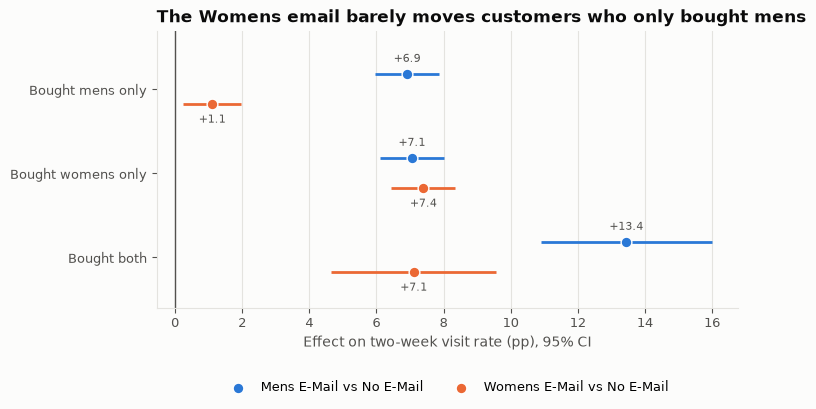

In [6]:
pg = seg[(seg["dimension"] == "purchase_group") & (seg["metric"] == "visit")]
level_labels = {"mens_only": "Bought mens only", "womens_only": "Bought womens only", "both": "Bought both"}
levels = ["mens_only", "womens_only", "both"]

fig, ax = plt.subplots(figsize=(7.5, 3.6))
y_base = np.arange(len(levels))[::-1]
for offset, email, dy, va in [(0.18, "mens", 7, "bottom"), (-0.18, "womens", -7, "top")]:
    sub = pg[pg["email"] == email].set_index("level").loc[levels]
    y = y_base + offset
    ax.hlines(y, 100 * sub["ci_low"], 100 * sub["ci_high"], color=ARM_COLORS[email], lw=2)
    ax.scatter(100 * sub["estimate"], y, s=60, color=ARM_COLORS[email], edgecolor="white", linewidth=1,
               zorder=3, label=f"{ARM_LABELS[email]} vs No E-Mail")
    for yi, est in zip(y, sub["estimate"]):
        ax.annotate(f"{100 * est:+.1f}", (100 * est, yi), xytext=(0, dy), textcoords="offset points",
                    ha="center", va=va, fontsize=8, color=TEXT_SECONDARY)
ax.axvline(0, color=TEXT_SECONDARY, lw=1)
ax.set_yticks(y_base, [level_labels[level] for level in levels])
ax.set_ylim(-0.6, len(levels) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on two-week visit rate (pp), 95% CI")
ax.set_title("The Womens email barely moves customers who only bought mens", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
save_figure(fig, "06_segment_effects_purchase_group")
plt.show()

### What the segment analysis shows

- **Past purchase category is the one dimension that clearly matters, and only for visits** (Holm-adjusted p < 0.001 for both emails).
  - The **Womens email** raises visits by about 7 pp among customers who bought women's items (alone or with men's), but only about **+1 pp** among customers who bought men's items only.
  - The **Mens email** works about equally well on mens-only and womens-only buyers (+7 pp each) and about twice as well on customers who bought both (+13 pp).
- **Channel:** no evidence that either email works differently for Phone, Web or Multichannel customers.
- **Past-year spend (`history_segment`):** the Mens visit effect drifts upward with past spend, and the Womens spend effect looks uneven across levels, but neither survives the Holm correction. With 12 heterogeneity tests, one raw p-value near 0.04 is what chance alone would produce.
- **Spend:** none of the spend heterogeneity tests survive correction. Spend effects within segments have intervals several times wider than their estimates, so the data cannot say whether spend responses differ between segments.

**Implication for targeting:** the clearest rule from these pre-specified segments is *don't send the Womens email to customers who only buy men's items*. Whether a model using all features together can find more than this is the question of the next section.

**What we cannot claim:** these are associations between pre-treatment characteristics and the size of the effect. They say *who* responds more, not *why*: for example, mens-only buyers may ignore the Womens email because of its content, or because of something else correlated with buying only men's items.

## 2. Uplift model, first attempt: T-learner with gradient boosting

### Set-up

- **Split:** 70% train / 30% test, stratified by arm, fixed seed. Models only see the training set; every number below is computed on the **test set**.
- **Features** (all pre-treatment): `recency`, `history`, `mens`, `womens`, `newbie`, `zip_code`, `channel`. `history_segment` and `purchase_group` are left out because they are coarser versions of `history` and `mens`/`womens`.
- **T-learner:** for each email, fit one outcome model on the email's customers and one on the control customers. A customer's predicted uplift is the difference between the two predictions:
  $$\hat\tau(x) = \hat\mu_{\text{email}}(x) - \hat\mu_{\text{control}}(x).$$
  Why a T-learner: the arms are balanced (1/3 each), so each model has ~15,000 training customers, and the method is easy to explain. The X-learner's main advantage, handling very unbalanced arms, does not apply here. Its known weakness: each model learns the *level* of the outcome, and the effect is a small difference between two noisy levels, so the model can invent heterogeneity that is not there.
- **First base model:** gradient boosting (`HistGradientBoosting`), chosen because it picks up interactions such as "bought both categories" automatically. Settings were fixed in advance to limit overfitting: depth 3, at least 100 customers per leaf, learning rate 0.05, early stopping on a validation split taken from the training data. They were not tuned on the test set.

### How the models are evaluated

**Uplift curve:** rank test customers by predicted uplift; for the top $k$, the incremental outcome is
$$\text{gain}(k) = \big(\bar y_{\text{email, top }k} - \bar y_{\text{control, top }k}\big) \times k.$$
Random targeting is the straight line from 0 to the overall effect. A useful model's curve lies above that line: it finds the responsive customers first.

**Summary number, "gain over random":** the area between the model's curve and the random line, with both axes divided by the number of customers. It is in outcome units: the average extra visits (or \$) per customer, across all targeting depths, from ranking by the model instead of at random. 0 means no better than random.

**Uncertainty:** 500 bootstrap resamples of the test customers with the predictions held fixed, giving a 95% interval. This captures the sampling noise of the test set, not the variation from re-training the model. The same resamples are used for every model, so models can be compared pairwise.

The curve is implemented in `hillstrom.uplift.uplift_curve`. `scikit-uplift` only accepts 0/1 outcomes, so it cannot evaluate spend; it is used in the tests to check that our curve matches it exactly on binary outcomes.

**Benchmark: the segment rule.** Score each test customer with their `purchase_group`'s effect estimated on the training set (three numbers per email). If a model cannot beat this, the extra complexity buys nothing.

In [7]:
from hillstrom.uplift import TLearner, bootstrap_gain_over_random, gain_over_random, make_features, split_train_test, uplift_curve

train, test = split_train_test(df)
print(f"train: {len(train):,} customers, test: {len(test):,} customers")


def arm_pair(data: pd.DataFrame, email: str) -> tuple[pd.DataFrame, np.ndarray]:
    # Customers in this email's arm or the control arm, and a treated indicator.
    sub = data[data["arm"].isin([email, "control"])]
    return sub, (sub["arm"] == email).to_numpy()


def model_scores(base: str, email: str, metric: str) -> tuple[np.ndarray, np.ndarray]:
    # Fit a T-learner on train; return predicted uplift for train and test customers.
    tr, treated_tr = arm_pair(train, email)
    te, _ = arm_pair(test, email)
    kind = "binary" if metric == "visit" else "continuous"
    model = TLearner(kind, base=base).fit(make_features(tr), tr[metric].to_numpy(), treated_tr)
    return model.predict_uplift(make_features(tr)), model.predict_uplift(make_features(te))


def rule_scores(email: str, metric: str) -> tuple[np.ndarray, np.ndarray]:
    # Segment rule: each customer gets their purchase_group's effect, estimated on train.
    tr, _ = arm_pair(train, email)
    te, _ = arm_pair(test, email)
    effect = {
        group: g.loc[g["arm"] == email, metric].mean() - g.loc[g["arm"] == "control", metric].mean()
        for group, g in tr.groupby("purchase_group")
    }
    return tr["purchase_group"].map(effect).to_numpy(), te["purchase_group"].map(effect).to_numpy()


results, draws, test_scores = [], {}, {}
UNIT = {"visit": ("pp", 100), "spend": ("$", 1)}


def record(name: str, email: str, metric: str, s_train: np.ndarray, s_test: np.ndarray) -> None:
    tr, treated_tr = arm_pair(train, email)
    te, treated_te = arm_pair(test, email)
    y_te = te[metric].to_numpy()
    d = bootstrap_gain_over_random(y_te, s_test, treated_te)
    draws[name, email, metric] = d
    test_scores[name, email, metric] = s_test
    results.append(
        {
            "model": name,
            "email": ARM_LABELS[email],
            "metric": metric,
            "train_gain": gain_over_random(tr[metric].to_numpy(), s_train, treated_tr),
            "test_gain": gain_over_random(y_te, s_test, treated_te),
            "ci_low": np.percentile(d, 2.5),
            "ci_high": np.percentile(d, 97.5),
        }
    )


def results_table(names: list[str]) -> pd.DataFrame:
    out = pd.DataFrame(results)
    out = out[out["model"].isin(names)].copy()
    for col in ["train_gain", "test_gain", "ci_low", "ci_high"]:
        out[col] = out.apply(lambda r: r[col] * UNIT[r["metric"]][1], axis=1)
    out["unit"] = out["metric"].map(lambda m: UNIT[m][0])
    out["beats_random"] = out["ci_low"] > 0
    return out

train: 44,800 customers, test: 19,200 customers


In [8]:
for email in EMAILS:
    for metric in ["visit", "spend"]:
        record("T-learner (gradient boosting)", email, metric, *model_scores("gbm", email, metric))

fmt = {"train_gain": "{:+.3f}", "test_gain": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}
results_table(["T-learner (gradient boosting)"]).style.format(fmt).hide(axis="index")

model,email,metric,train_gain,test_gain,ci_low,ci_high,unit,beats_random
T-learner (gradient boosting),Mens E-Mail,visit,+1.369,+0.068,-0.320,+0.413,pp,False
T-learner (gradient boosting),Mens E-Mail,spend,+0.333,+0.094,-0.053,+0.250,$,False
T-learner (gradient boosting),Womens E-Mail,visit,+1.593,+0.603,+0.256,+0.973,pp,True
T-learner (gradient boosting),Womens E-Mail,spend,+0.285,+0.053,-0.072,+0.181,$,False


**The first model failed.** Only the Womens visit model beats random targeting on the test set. The Mens visit model, where the segment analysis found clear heterogeneity, is no better than random, and neither spend model is.

The gap between training and test gain shows why: on the training customers, the Mens visit model looks about 20 times better than on the test customers. It has learned noise in the training data.

A look inside the Mens visit model confirms that the code is not at fault and points to the cause. The model does find the real pattern, higher uplift for customers who bought both categories, but the spread of its predictions *within* each group is as large as the difference *between* groups. Inside each group, customers are ranked mostly by noise, and that noise drowns out the real signal.

In [9]:
te_mens, treated_mens = arm_pair(test, "mens")
pred = pd.Series(test_scores["T-learner (gradient boosting)", "mens", "visit"], index=te_mens.index)
observed = te_mens.groupby("purchase_group").apply(
    lambda g: g.loc[g["arm"] == "mens", "visit"].mean() - g.loc[g["arm"] == "control", "visit"].mean()
)
pd.DataFrame(
    {
        "predicted_uplift_mean": pred.groupby(te_mens["purchase_group"]).mean(),
        "predicted_uplift_sd": pred.groupby(te_mens["purchase_group"]).std(),
        "observed_effect_in_test": observed,
    }
).style.format("{:+.3f}")

,predicted_uplift_mean,predicted_uplift_sd,observed_effect_in_test
purchase_group,,,
both,+0.099,+0.053,+0.168
mens_only,+0.075,+0.029,+0.065
womens_only,+0.075,+0.029,+0.063


## 3. Second attempt: T-learner with linear models

> **How this section came about.** The model above was the pre-planned one. After seeing that it overfit, we tried **one** alternative, chosen for a stated reason before seeing its results: a T-learner with linear base models (logistic regression for visit, ordinary least squares for spend), which cannot produce the sharp, noisy within-group differences that the trees did. Nothing else changed: same features, same split, same evaluation.
>
> Because the test set has now been used twice, the result of this second model is slightly optimistic. We limited that by trying a single, pre-stated alternative rather than searching over many models and keeping the best one. A fully clean comparison would need a fresh test set, which this dataset does not have.

Settings: logistic regression with scikit-learn's default L2 penalty (C = 1) on standardized features; OLS for spend. OLS on a zero-heavy outcome is fine here: it estimates the best linear approximation of mean spend, and the uplift is a difference in means.

Not done on purpose: adding a hand-made "bought both categories" interaction feature. That idea comes from the segment analysis in section 1, which used all customers, including the test set; building it into the model would tailor the model to the test data.

In [10]:
for email in EMAILS:
    for metric in ["visit", "spend"]:
        record("T-learner (linear)", email, metric, *model_scores("linear", email, metric))

results_table(["T-learner (gradient boosting)", "T-learner (linear)"]).style.format(fmt).hide(axis="index")

model,email,metric,train_gain,test_gain,ci_low,ci_high,unit,beats_random
T-learner (gradient boosting),Mens E-Mail,visit,+1.369,+0.068,-0.320,+0.413,pp,False
T-learner (gradient boosting),Mens E-Mail,spend,+0.333,+0.094,-0.053,+0.250,$,False
T-learner (gradient boosting),Womens E-Mail,visit,+1.593,+0.603,+0.256,+0.973,pp,True
T-learner (gradient boosting),Womens E-Mail,spend,+0.285,+0.053,-0.072,+0.181,$,False
T-learner (linear),Mens E-Mail,visit,+0.365,+0.404,+0.026,+0.719,pp,True
T-learner (linear),Mens E-Mail,spend,+0.143,+0.025,-0.147,+0.174,$,False
T-learner (linear),Womens E-Mail,visit,+0.892,+0.765,+0.429,+1.091,pp,True
T-learner (linear),Womens E-Mail,spend,+0.168,+0.070,-0.064,+0.180,$,False


**Visit:** the overfitting is gone; training and test gains are now close for both emails, and both visit models beat random targeting on the test set.

**Spend:** neither linear spend model beats random targeting, and the training gain is still several times the test gain. The number of buyers in the test set shows why spend uplift is so hard to evaluate, let alone learn:

In [11]:
test.groupby("arm")["conversion"].sum().rename("buyers_in_test_set").to_frame()

,buyers_in_test_set
arm,
control,38
mens,86
womens,52


Every spend ranking is judged on a few dozen buyers per arm. Individual spend uplift cannot be learned or verified reliably from this data with either model.

## 4. Models vs the simple segment rule

The final question for this notebook: does either model find anything that the three-group `purchase_group` rule does not?

A caveat on the rule itself. The `purchase_group` dimension was pre-specified in the design document, and the rule's three effects are estimated on the training set only. But it was picked as *the* benchmark after section 1, which looked at all customers including the test set, so the rule's test performance is slightly optimistic too.

In [12]:
for email in EMAILS:
    for metric in ["visit", "spend"]:
        record("Segment rule (purchase_group)", email, metric, *rule_scores(email, metric))

MODELS = ["T-learner (gradient boosting)", "T-learner (linear)", "Segment rule (purchase_group)"]
results_table(MODELS).sort_values(["metric", "email"], key=lambda c: c.map({"visit": 0, "spend": 1}) if c.name == "metric" else c, kind="stable").style.format(fmt).hide(axis="index")

model,email,metric,train_gain,test_gain,ci_low,ci_high,unit,beats_random
T-learner (gradient boosting),Mens E-Mail,visit,+1.369,+0.068,-0.320,+0.413,pp,False
T-learner (linear),Mens E-Mail,visit,+0.365,+0.404,+0.026,+0.719,pp,True
Segment rule (purchase_group),Mens E-Mail,visit,+0.246,+0.457,+0.141,+0.804,pp,True
T-learner (gradient boosting),Womens E-Mail,visit,+1.593,+0.603,+0.256,+0.973,pp,True
T-learner (linear),Womens E-Mail,visit,+0.892,+0.765,+0.429,+1.091,pp,True
Segment rule (purchase_group),Womens E-Mail,visit,+0.770,+0.790,+0.517,+1.062,pp,True
T-learner (gradient boosting),Mens E-Mail,spend,+0.333,+0.094,-0.053,+0.250,$,False
T-learner (linear),Mens E-Mail,spend,+0.143,+0.025,-0.147,+0.174,$,False
Segment rule (purchase_group),Mens E-Mail,spend,+0.040,+0.109,-0.029,+0.257,$,False
T-learner (gradient boosting),Womens E-Mail,spend,+0.285,+0.053,-0.072,+0.181,$,False


Because every method was scored on the same bootstrap resamples, the difference between two methods can be summarized directly. The table shows each model's gain minus the rule's gain, with a 95% interval.

In [13]:
diff_rows = []
for model in MODELS[:2]:
    for email in EMAILS:
        for metric in ["visit", "spend"]:
            d = (draws[model, email, metric] - draws[MODELS[2], email, metric]) * UNIT[metric][1]
            diff_rows.append(
                {
                    "model": model,
                    "email": ARM_LABELS[email],
                    "metric": metric,
                    "gain_minus_rule": d.mean(),
                    "ci_low": np.percentile(d, 2.5),
                    "ci_high": np.percentile(d, 97.5),
                    "unit": UNIT[metric][0],
                }
            )
pd.DataFrame(diff_rows).style.format(
    {"gain_minus_rule": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"}
).hide(axis="index")

model,email,metric,gain_minus_rule,ci_low,ci_high,unit
T-learner (gradient boosting),Mens E-Mail,visit,-0.404,-0.908,+0.062,pp
T-learner (gradient boosting),Mens E-Mail,spend,-0.020,-0.193,+0.142,$
T-learner (gradient boosting),Womens E-Mail,visit,-0.187,-0.474,+0.096,pp
T-learner (gradient boosting),Womens E-Mail,spend,+0.058,-0.067,+0.189,$
T-learner (linear),Mens E-Mail,visit,-0.081,-0.440,+0.220,pp
T-learner (linear),Mens E-Mail,spend,-0.090,-0.267,+0.084,$
T-learner (linear),Womens E-Mail,visit,-0.017,-0.233,+0.194,pp
T-learner (linear),Womens E-Mail,spend,+0.072,-0.091,+0.228,$


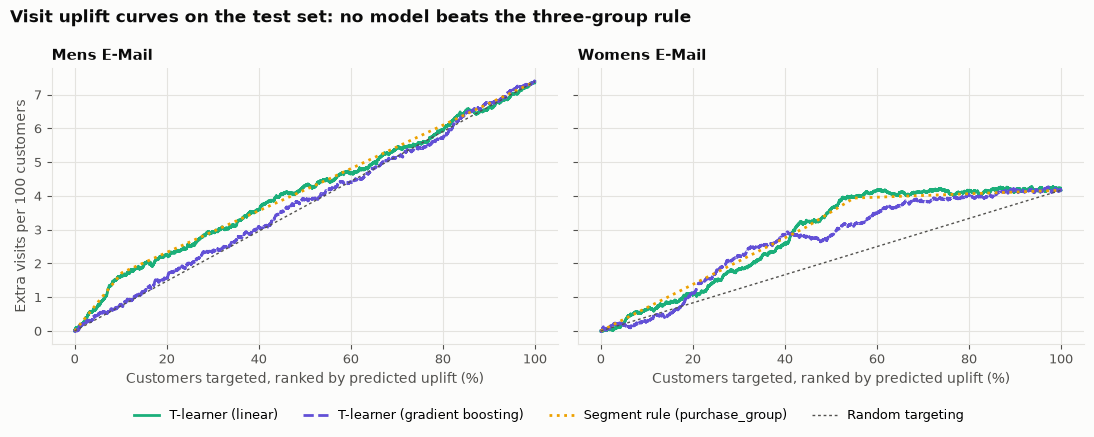

In [14]:
MODEL_STYLES = {
    "T-learner (linear)": dict(color="#1baf7a", ls="-"),
    "T-learner (gradient boosting)": dict(color="#6250d6", ls="--"),
    "Segment rule (purchase_group)": dict(color="#eda100", ls=":"),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, email in zip(axes, EMAILS):
    te, treated_te = arm_pair(test, email)
    y = te["visit"].to_numpy()
    for model, style in MODEL_STYLES.items():
        k, gain = uplift_curve(y, test_scores[model, email, "visit"], treated_te)
        ax.plot(100 * k / k[-1], 100 * gain / k[-1], lw=2, label=model, **style)
    ax.plot([0, 100], [0, 100 * gain[-1] / k[-1]], color=TEXT_SECONDARY, lw=1, ls=(0, (2, 2)), label="Random targeting")
    ax.set_title(ARM_LABELS[email], loc="left", fontsize=11)
    ax.set_xlabel("Customers targeted, ranked by predicted uplift (%)")
axes[0].set_ylabel("Extra visits per 100 customers")
fig.suptitle("Visit uplift curves on the test set: no model beats the three-group rule",
             x=0.01, ha="left", fontweight="bold", color=TEXT_PRIMARY)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=4)
fig.tight_layout()
save_figure(fig, "06_uplift_curves_visit")
plt.show()

## Takeaways

**What we found**

- **Visit:** the linear T-learner beats random targeting for both emails, but only narrowly for the Mens email (the interval's lower end is close to zero). It is **not better than the simple three-group rule**: the differences are small and their intervals include zero. All the targeting value that the data reveals for visits is captured by one variable, the customer's past purchase category.
- **The Womens email has a clear saturation point:** its uplift curve flattens after roughly the top 55% of customers. Almost all of its extra visits come from customers who have bought women's items; sending it to the rest (mostly mens-only buyers) adds close to nothing. For the Mens email, the curves stay close to the random line: its effect is spread fairly evenly across customers, so ranking matters less.
- **Spend:** no method beats random targeting on spend. With a few dozen buyers per arm in the test set, individual spend uplift can neither be learned nor verified from this data.
- **The pre-planned gradient-boosting model overfit**, a known weakness of T-learners when the effect is small relative to the outcome's own variation. A simpler linear model fixed the overfitting but did not add value beyond the rule.

**What this means for targeting (notebook 07)**

- Spend-based targeting is not supported by the data, as the design document anticipated. The policy will rank customers on **visit uplift** and report the spend consequences with uncertainty.
- Both the segment rule and the linear T-learner will be evaluated as policies. If they perform the same, the rule is preferable: three numbers that a marketing team can read and check.

**What we cannot claim**

- That machine learning is useless for this problem in general. With more data, a longer outcome window, or richer customer features, a model may find more. This dataset has 7 coarse features and ~1% buyers.
- That the linear model's test result is fully clean: the test set was used twice (first and second attempt).
- Why customers respond differently. The models and segments describe who responds, not the reason.